In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

In [2]:
# Create a list for Cell IDs
cells = ["Cell_1", "Cell_2", "Cell_3", "Cell_4"]
# Create a list to hold expression values for Gene A across all of the cells
Gene_A = [0, 12, 65, 23]
# Create a list to hold expression values for Gene B across all of the cells
Gene_B = [4, 30, 57, 18]

# Create a DataFrame to hold the cell names and expression values
expression_df = pd.DataFrame({
    "cells": cells,
    "Gene_A": Gene_A,
    "Gene_B": Gene_B
}).set_index("cells") 
cells
# View the expression dataframe
expression_df


,Gene_A,Gene_B
cells,,
Cell_1,0,4
Cell_2,12,30
Cell_3,65,57
Cell_4,23,18


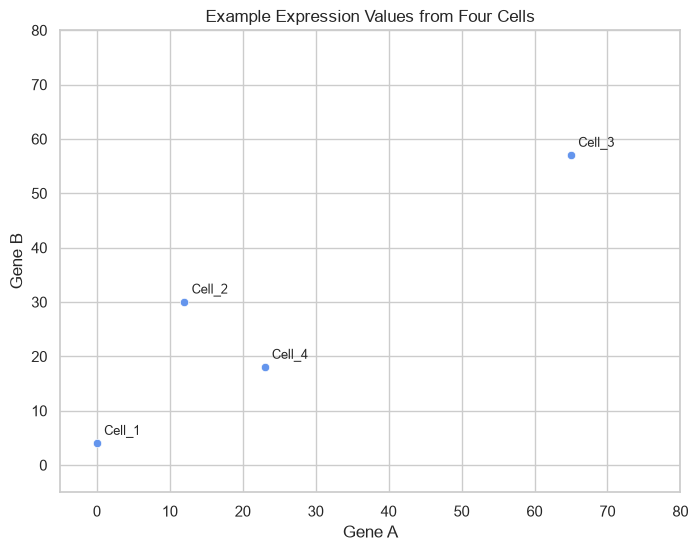

In [3]:
# Set the theme to "whitegrid"
sns.set(style="whitegrid")

# Initialize a plot with a specific size
plt.figure(figsize = (8, 6))

# Add a scatterplot layer to the plot
expression_plot = sns.scatterplot(data = expression_df,
                x = "Gene_A", 
                y = "Gene_B",
                color = "cornflowerblue")

# Set x-axis limits
plt.xlim(left = -5,
         right = 80)

# Set y-axis limits
plt.ylim(bottom = -5,
         top = 80)

# Add Cell labels
for cell_id, row in expression_df.iterrows():
    expression_plot.text(
        x = row["Gene_A"] + 1,
        y = row["Gene_B"] + 1,
        s = cell_id,
        fontsize = 9,
        ha = "left",
        va = "bottom"
    )

# Change the text of the x-axis label
plt.xlabel(xlabel = "Gene A")

# Change the text of the y-axis label
plt.ylabel(ylabel = "Gene B")

# Add plot title
plt.title(label = "Example Expression Values from Four Cells")

# Render the plot
plt.show()

In [4]:
# Determine the center of the data by:
# Finding the average expression of gene A
Gene_A_mean = expression_df["Gene_A"].mean()
# Finding the average expression of gene B
Gene_B_mean = expression_df["Gene_B"].mean()

center_of_data = {
    "Gene_A": Gene_A_mean,
    "Gene_B": Gene_B_mean,
}

# Print out the center_of_data dictionary
print(center_of_data)

{'Gene_A': np.float64(25.0), 'Gene_B': np.float64(27.25)}


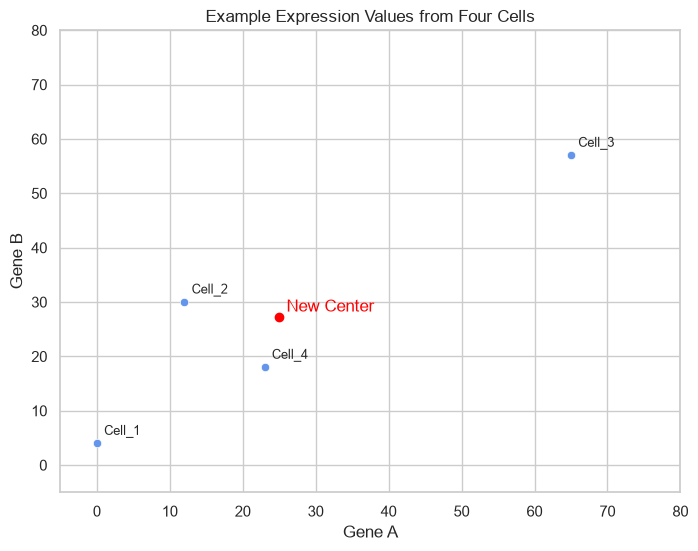

In [5]:
# Set the theme to "whitegrid"
sns.set(style="whitegrid")

# Initialize a plot with a specific size
plt.figure(figsize = (8, 6))

# Add a scatterplot layer to the plot
expression_plot = sns.scatterplot(data = expression_df,
                x = "Gene_A", 
                y = "Gene_B",
                color = "cornflowerblue")

# Set x-axis limits
plt.xlim(left = -5,
         right = 80)

# Set y-axis limits
plt.ylim(bottom = -5,
         top = 80)

# Add Cell labels
for cell_id, row in expression_df.iterrows():
    expression_plot.text(
        x = row["Gene_A"] + 1,
        y = row["Gene_B"] + 1,
        s = cell_id,
        fontsize = 9,
        ha = "left",
        va = "bottom"
    )

# Add the new center in red
expression_plot.scatter(x = Gene_A_mean,
             y = Gene_B_mean,
             color = "red")

# Add label for new center
expression_plot.text(x = Gene_A_mean + 1,
          y = Gene_B_mean + 1,
          s = "New Center",
          color = "red")

# Change the text of the x-axis label
plt.xlabel(xlabel = "Gene A")

# Change the text of the y-axis label
plt.ylabel(ylabel = "Gene B")

# Add plot title
plt.title(label = "Example Expression Values from Four Cells")

# Render the plot
plt.show()

In [6]:
# Shift the data so it is centered on the origin
recentered_expression_df = expression_df.assign(
    Gene_A = expression_df["Gene_A"] - Gene_A_mean,
    Gene_B = expression_df["Gene_B"] - Gene_B_mean
)

# Print out the re-centered data
print(recentered_expression_df)

        Gene_A  Gene_B
cells                 
Cell_1   -25.0  -23.25
Cell_2   -13.0    2.75
Cell_3    40.0   29.75
Cell_4    -2.0   -9.25


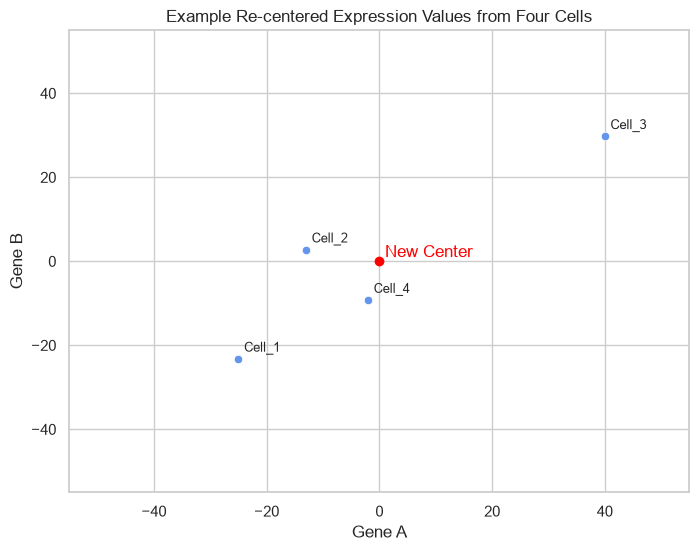

In [7]:
# Set the theme to "whitegrid"
sns.set(style="whitegrid")

# Initialize a plot with a specific size
plt.figure(figsize = (8, 6))

# Add a scatterplot layer to the plot
recentered_expression_plot = sns.scatterplot(data = recentered_expression_df,
                x = "Gene_A", 
                y = "Gene_B",
                color = "cornflowerblue")

# Set x-axis limits
plt.xlim(left = -55,
         right = 55)

# Set y-axis limits
plt.ylim(bottom = -55,
         top = 55)

# Add Cell labels
for cell_id, row in recentered_expression_df.iterrows():
    recentered_expression_plot.text(
        x = row["Gene_A"] + 1,
        y = row["Gene_B"] + 1,
        s = cell_id,
        fontsize = 9,
        ha = "left",
        va = "bottom"
    )

# Add the new center in red
recentered_expression_plot.scatter(x = 0,
             y = 0,
             color = "red")

# Add label for new center
recentered_expression_plot.text(x = 1,
          y = 1,
          s = "New Center",
          color = "red")

# Change the text of the x-axis label
plt.xlabel(xlabel = "Gene A")

# Change the text of the y-axis label
plt.ylabel(ylabel = "Gene B")

# Add plot title
plt.title(label = "Example Re-centered Expression Values from Four Cells")

# Render the plot
plt.show()

In [8]:
# Create a covariance matrix
cov_matrix = recentered_expression_df.cov()

# Print out the covariance matrix
print(cov_matrix)

            Gene_A      Gene_B
Gene_A  799.333333  584.666667
Gene_B  584.666667  506.250000


In [9]:
# Or you can use the covariance function
print(recentered_expression_df["Gene_A"].cov(recentered_expression_df["Gene_B"]))

584.6666666666666


In [10]:
# Find the eigenvalues and eigenvectors of the covariance matrix
eig_values, eig_vectors = np.linalg.eigh(cov_matrix)

# Sort the eigenvalues and eigenvectors by descending variance explained
# Indices for descending order
idx = np.argsort(eig_values)[::-1]
# Reordered eigenvalues
eig_values = eig_values[idx]
# Reordered eigenvectors
eig_vectors = eig_vectors[:, idx] 

# Print out the eigenvalues
print(f"The eigenvalues are:\n{eig_values}")

The eigenvalues are:
[1255.54333293   50.04000041]


In [11]:
pc_scores = recentered_expression_df.values.dot(eig_vectors)
print(pc_scores)

[[ 34.01258088   2.95073584]
 [  8.55735526 -10.16534165]
 [-49.83708078   1.15233654]
 [  7.26714464   6.06226928]]


In [12]:
pc_scores_df = pd.DataFrame(
    pc_scores,
    index = recentered_expression_df.index,
    columns = ["PC_1", "PC_2"]
)

print(pc_scores_df)

             PC_1       PC_2
cells                       
Cell_1  34.012581   2.950736
Cell_2   8.557355 -10.165342
Cell_3 -49.837081   1.152337
Cell_4   7.267145   6.062269


In [13]:
# Calculate the percent of variance explained by each PC using the eigenvalues
pct_var_explained = (eig_values / eig_values.sum()) * 100

print(f"Percent of variance explained by PC1: {pct_var_explained[0]}%\nPercent of variance explained by PC2: {pct_var_explained[1]}%")

Percent of variance explained by PC1: 96.16723045339522%
Percent of variance explained by PC2: 3.83276954660478%


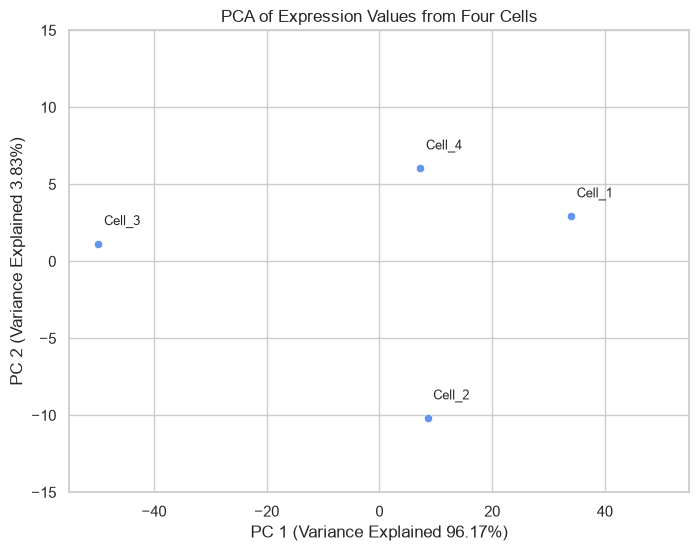

In [14]:
# Set the theme to "whitegrid"
sns.set(style="whitegrid")

# Initialize a plot with a specific size
plt.figure(figsize = (8, 6))

# Add a scatterplot layer to the plot
PCA_plot = sns.scatterplot(data = pc_scores_df,
                x = "PC_1", 
                y = "PC_2",
                color = "cornflowerblue")

# Set x-axis limits
plt.xlim(left = -55,
         right = 55)

# Set y-axis limits
plt.ylim(bottom = -15,
         top = 15)

# Add cell labels at PC coordinates
for cell_id, row in pc_scores_df.iterrows():
    PCA_plot.text(
        x = row["PC_1"] + 1,
        y = row["PC_2"] + 1,
        s = cell_id,
        fontsize = 9,
        ha = "left",
        va = "bottom"
    )

# Change the text of the x-axis label
plt.xlabel(xlabel = f"PC 1 (Variance Explained {pct_var_explained[0].round(2)}%)")

# Change the text of the y-axis label
plt.ylabel(ylabel = f"PC 2 (Variance Explained {pct_var_explained[1].round(2)}%)")

# Add plot title
plt.title(label = "PCA of Expression Values from Four Cells")

# Render the plot
plt.show()

In [15]:
# Create PCA object
pca_sklearn = PCA()

# Run PCA on our expression data
pc_scores_sklearn = pca_sklearn.fit_transform(expression_df)


In [17]:
# Print the center of the data found by scikit-learn
print(pca_sklearn.mean_)

# Print the eigenvalues found by scikit-learn
print(pca_sklearn.explained_variance_)

[25.   27.25]
[1255.54333293   50.04000041]


In [18]:
# Create a dataframe to hold the eigenvectors found by scikit-learn
eigenvector_sklearn = pd.DataFrame(
    pca_sklearn.components_.T
)

# Print the eigenvectorsfound by scikit-learn
print(eigenvector_sklearn)

          0         1
0  0.788391 -0.615174
1  0.615174  0.788391


In [19]:
# Create a dataframe to hold the PC scores found by scikit-learn
pc_scores_sklearn_df = pd.DataFrame(
    pc_scores_sklearn,
    index = expression_df.index,
    columns = ["PC_1", "PC_2"]
)

# Print the PC scores found by scikit-learn
pc_scores_sklearn_df

,PC_1,PC_2
cells,,
Cell_1,-34.012581,-2.950736
Cell_2,-8.557355,10.165342
Cell_3,49.837081,-1.152337
Cell_4,-7.267145,-6.062269
